<a href="https://colab.research.google.com/github/anaghahegde326/BIS_LAB/blob/main/BIS_LAB5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Optimal Thresholds: [ 77.01520079 136.40172753 184.10649445]
Best Fitness: 5270.003403347322


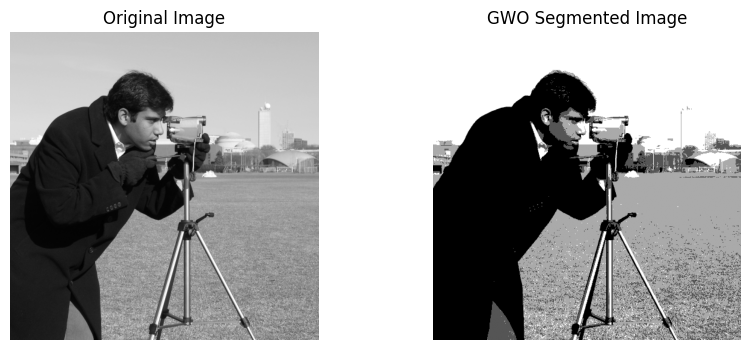

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

# Load a sample grayscale image from skimage
img = data.camera()

if img is None:
    raise ValueError("Image not found!")

# Calculate histogram
hist, _ = np.histogram(img, bins=256, range=(0, 256))
prob = hist / hist.sum()
levels = np.arange(256)

# Fitness function: Multilevel Otsu between-class variance
def fitness(thresholds):
    t = np.sort(np.clip(np.round(thresholds).astype(int), 1, 254))
    boundaries = [0] + list(t) + [256]

    score = 0
    for i in range(len(boundaries) - 1):
        p = prob[boundaries[i]:boundaries[i + 1]]
        if p.sum() == 0:
            continue

        mean = np.sum(
            levels[boundaries[i]:boundaries[i + 1]] * p
        ) / p.sum()

        score += p.sum() * (mean - np.sum(levels * prob)) ** 2

    return score

# GWO parameters
wolves = 10
iterations = 30
dimensions = 3

# Initialize wolves
positions = np.random.randint(
    1, 255, (wolves, dimensions)
).astype(float)

best_alpha = None
best_score = -1

# Grey Wolf Optimization
for iteration in range(iterations):

    scores = [fitness(w) for w in positions]

    order = np.argsort(scores)[::-1]
    alpha = positions[order[0]].copy()
    beta = positions[order[1]].copy()
    delta = positions[order[2]].copy()

    if scores[order[0]] > best_score:
        best_score = scores[order[0]]
        best_alpha = alpha.copy()

    a = 2 - 2 * iteration / iterations

    for i in range(wolves):
        new_position = np.zeros(dimensions)

        for leader in [alpha, beta, delta]:
            A = 2 * a * np.random.rand(dimensions) - a
            C = 2 * np.random.rand(dimensions)

            D = np.abs(C * leader - positions[i])
            X = leader - A * D

            new_position += X / 3

        positions[i] = np.clip(new_position, 1, 254)

print("Optimal Thresholds:", np.sort(best_alpha))
print("Best Fitness:", best_score)

# Segment image using optimal thresholds
thresholds = np.sort(best_alpha)
segmented = np.digitize(img, thresholds)

# Display results
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(segmented, cmap="gray")
plt.title("GWO Segmented Image")
plt.axis("off")

plt.show()

Optimal Log Parameter: 1.002776499557211
Optimal Denoising Sigma: 0.3629732256525757
Best Fitness: 7.024121843468279


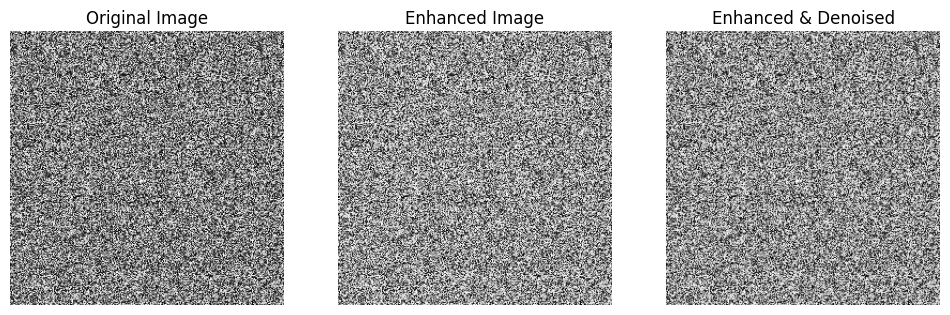

In [5]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load MRI image
img = cv2.imread("mri.jpg", 0)

if img is None:
    raise ValueError("MRI image not found!")

# Normalize image
img = img.astype(np.float32) / 255.0

# Fitness function
def fitness(params):
    c, sigma = params

    # Logarithmic transformation
    enhanced = c * np.log1p(img) / np.log(2)
    enhanced = np.clip(enhanced, 0, 1)

    # Gaussian filtering for noise reduction
    enhanced = cv2.GaussianBlur(
        enhanced, (5, 5), sigma
    )

    # Calculate image entropy
    hist, _ = np.histogram(
        enhanced, bins=256, range=(0, 1)
    )
    prob = hist / hist.sum()
    prob = prob[prob > 0]

    entropy = -np.sum(prob * np.log2(prob))

    # Calculate contrast
    contrast = np.std(enhanced)

    # Estimate noise
    median = cv2.medianBlur(
        enhanced.astype(np.float32), 3
    )
    noise = np.mean(np.abs(enhanced - median))

    return entropy + 0.5 * contrast - 5 * noise

# GWO parameters
wolves = 10
iterations = 30
dimensions = 2

# Parameter ranges: c and Gaussian sigma
lower = np.array([0.5, 0.0])
upper = np.array([1.5, 3.0])

# Initialize wolves
positions = np.random.uniform(
    lower, upper, (wolves, dimensions)
)

best_alpha = None
best_score = -float("inf")

# Grey Wolf Optimization
for iteration in range(iterations):

    scores = [fitness(w) for w in positions]

    order = np.argsort(scores)[::-1]

    alpha = positions[order[0]].copy()
    beta = positions[order[1]].copy()
    delta = positions[order[2]].copy()

    if scores[order[0]] > best_score:
        best_score = scores[order[0]]
        best_alpha = alpha.copy()

    a = 2 - 2 * iteration / iterations

    for i in range(wolves):
        new_position = np.zeros(dimensions)

        for leader in [alpha, beta, delta]:
            A = 2 * a * np.random.rand(dimensions) - a
            C = 2 * np.random.rand(dimensions)

            D = np.abs(C * leader - positions[i])
            X = leader - A * D

            new_position += X / 3

        positions[i] = np.clip(
            new_position, lower, upper
        )

# Apply best parameters
c, sigma = best_alpha

enhanced = c * np.log1p(img) / np.log(2)
enhanced = np.clip(enhanced, 0, 1)

denoised = cv2.GaussianBlur(
    enhanced.astype(np.float32),
    (5, 5),
    sigma
)

print("Optimal Log Parameter:", c)
print("Optimal Denoising Sigma:", sigma)
print("Best Fitness:", best_score)

# Display results
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(enhanced, cmap="gray")
plt.title("Enhanced MRI")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(denoised, cmap="gray")
plt.title("Enhanced and Denoised MRI")
plt.axis("off")

plt.show()
